# Read-backed phasing

Two heterozygous sites tell us which alleles are present. A fragment that spans both also tells us which alleles occur on one chromosome copy.

A diploid genotype at each of two sites can be 0/1 in both individuals even if one carries 0–0 and 1–1 and the other carries 0–1 and 1–0. The phase is the ordering across sites on the same copy. Swapping both copy labels within a block changes its name, but preserves every within-block relationship.

In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
root = next(p for p in (here, *here.parents) if (p / "haplotype.py").is_file())
sys.path.insert(0, str(root))
from demo_data import make_fixture
from haplotype import load_sites, fragment_patterns, phase

## Phase a known example

Six artificial fragments cover three markers. A fourth marker is present in the variant file and has no spanning observation. Insertions, a deletion and soft clipping test the alignment-coordinate mapping.

In [2]:
with TemporaryDirectory() as directory:
    vcf, bam = make_fixture(directory)
    sample, sites = load_sites(vcf)
    patterns = fragment_patterns(bam, sites, sample)
    rows, edges = phase(sites, patterns)
print("Position | block | haplotype 1 | haplotype 2 | observed fragments")
for _, pos, ref, alt, block, h1, h2, n in rows:
    print(pos, block, h1, h2, n, sep="   ")
linked = [r for r in rows if r[4] != "."]
truth = {5: 0, 10: 1, 17: 0}
switches = sum(
    (left[5] ^ right[5]) != (truth[left[1]] ^ truth[right[1]])
    for left, right in zip(linked, linked[1:])
)
print(
    f"Linked markers {len(linked)}/{len(rows)} | switch errors {switches}/{len(linked)-1} comparable transitions"
)
assert len(linked) == 3 and switches == 0

Position | block | haplotype 1 | haplotype 2 | observed fragments
5   5   0   1   6
10   5   1   0   6
17   5   0   1   6
27   .   .   .   0
Linked markers 3/4 | switch errors 0/2 comparable transitions


## Read the fragment evidence

Each row is one distinct fragment allele pattern. The count in its label shows how many molecules support it. White positions have no observation.

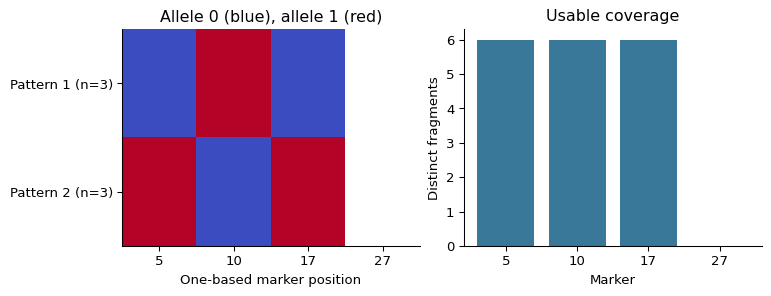

In [3]:
pos = [r[1] for r in rows]
observed = list(patterns["markers"].items())
mat = np.full((len(observed), len(pos)), np.nan)
for i, (pattern, n) in enumerate(observed):
    for p, b in pattern:
        mat[i, pos.index(p)] = b
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
a.imshow(mat, aspect="auto", vmin=0, vmax=1, cmap="coolwarm")
a.set(
    xticks=range(len(pos)),
    xticklabels=pos,
    yticks=range(len(observed)),
    yticklabels=[f"Pattern {i+1} (n={n})" for i, (_, n) in enumerate(observed)],
    xlabel="One-based marker position",
    title="Allele 0 (blue), allele 1 (red)",
)
b.bar([str(x) for x in pos], [r[-1] for r in rows], color="#397899")
b.set(xlabel="Marker", ylabel="Distinct fragments", title="Usable coverage")
plt.show()

## Interpreting the result

The unobserved fourth marker has a known genotype and unresolved phase. Phase labels restart at each disconnected block. A switch error compares successive heterozygous sites within the same truth and inferred block.

## Exercise

Lower the support of one link to a tie. Trace how the assignment and the number of comparable transitions change.

## References

[NHGRI, Haplotype](https://www.genome.gov/genetics-glossary/haplotype)

[GA4GH, SAM and VCF specifications](https://samtools.github.io/hts-specs/)

[WhatsHap, read-based phasing](https://whatshap.readthedocs.io/en/latest/guide.html)